# Phase-fixed weighted Gerchberg-Saxton against slmsuite

**Question:** Does DinHot's phase-fixed weighted Gerchberg-Saxton match the state of the art, slmsuite's weighted algorithms run on the same 1024-trap target and grid, in efficiency, uniformity and the number of iterations to get there?

- **Level:** 3, State of the art
- **Prerequisites:** notebook 02 of this topic
- **Reading time:** about 50 minutes

## Objectives

On arrays of thousands of sites, such as the 6,100 atoms in about 12,000 tweezers of recent work (Manetsch et al. 2025), the uniformity of the weighted algorithm is the limit of the experiment, and the field settled on one practical algorithm: weighted Gerchberg-Saxton that freezes the focal-plane phase after a dozen iterations (Kim et al. 2019). DinHot implements it as M07. The claim to test is not that DinHot beats anyone: it is that its implementation is a faithful member of the state of the art, so that every later notebook can use it as the baseline. You will run M06 and M07 on the 1024 traps of case C03, run slmsuite 0.5.0, an open-source library with the same algorithms, with its Leonardo and Kim weights on the same traps, the same FFT grid, the same Gaussian beam and the same start phase, score all of them with the same metrics, and read the difference in the figure and in the table. A comparison is only a comparison of the codes when everything else is equal, so every run of a seed, in DinHot and in slmsuite, starts from one and the same SLM phase.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, the pipeline's modules by path, and the pinned reference implementation
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
import slmsuite
from slmsuite.holography.algorithms import SpotHologram

slmsuite.configure_logging(None)  # no console log inside the outputs

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))


def trap_numbers(phi, setup, traps):
    """Efficiency, uniformity and relative spread (percent) of a hologram, read on the FFT grid."""
    v = forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, traps)
    i = metrics.trap_intensities(v)
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)


def first_below(curve, percent):
    """The first iteration (1-based) whose spread is below ``percent``, or None."""
    return next((k + 1 for k, row in enumerate(curve) if row[2] < percent), None)

numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot, for the case; slmsuite is an open-source library for holography on SLMs, MIT licence, pinned at 0.5.0 (https://pypi.org/project/slmsuite/).
- Licence class: synthetic case written by the product, no third-party dataset; the reference implementation is used as a library under its own licence.
- File read: `data/examples/cases.json`, case C03, a 32 by 32 lattice of 1024 traps on the 256 by 256 pixel SLM, with the case seed and the next one.

In [2]:
# case C03: 1024 traps, 32 x 32, on the 256 x 256 pixel SLM; both implementations get this array and this beam
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C03_large_array"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
seeds = [rec["seed"], rec["seed"] + 1]
# one start phase per seed, uniform on the SLM, handed to every method of the notebook
starts = {seed: np.random.default_rng(seed).uniform(-np.pi, np.pi, (setup.n_pix, setup.n_pix)) for seed in seeds}
iy, ix = forward.trap_bins(setup, traps)
spots = np.vstack([ix, iy])
print(f"{len(traps)} traps, focal bin {geometry.focal_bin_m(setup) * 1e6:.3f} um")
print(f"{rec['budget']['iterations']} iterations in the budget")
print(f"traps per SLM pixel: {len(traps) / setup.n_pix**2 * 100:.2f} % of the pixels")

1024 traps, focal bin 0.498 um
30 iterations in the budget
traps per SLM pixel: 1.56 % of the pixels


## Method

The weighted update of notebook 02 is $w_m \leftarrow w_m \langle r\rangle/r_m$ with $r_m = |V_m|/a_m$, and the request is $c_m = w_m a_m e^{i\psi_m}$ with $\psi_m = \arg V_m$ (Di Leonardo et al. 2007, https://doi.org/10.1364/OE.15.001913). The phase-fixed variant (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178; M07 in the product) follows the field for the first $N$ iterations, $\psi_i = \arg V_m^{i}$, and then freezes it, $\psi_i = \psi_N$ for $i \geq N$, so that the later iterations only adjust amplitudes. Kim reports a modulation efficiency of 91.2 percent for 1500 foci with $N = 12$; the product takes $N = 12$ as its default. With 1024 traps on a 256 by 256 SLM there are 64 pixels per trap, so this is a crowded hologram, which is the regime where the algorithm matters. The next cells run the product's two weighted methods from the start phases of the data cell (one uniform random SLM phase per seed, passed as `init`) and ask when freezing helps.

The first cell runs weighted Gerchberg-Saxton (M06) and the phase-fixed variant (M07) for the 30 iterations of the case, from two seeds each. It reports the mean of the final efficiency, uniformity and spread over the seeds and the first iteration at which each seed's spread falls under 1 percent.

In [3]:
# DinHot: weighted GS (M06) and phase-fixed WGS (M07, the phase is frozen after 12 iterations), two seeds each
budget = Budget(rec["budget"]["iterations"])
product = {"M06": [], "M07": []}
for seed in seeds:
    product["M06"].append(m06_gsw.run(setup, target, budget=budget, rng=Rng(seed), init=starts[seed]))
    product["M07"].append(m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(seed), init=starts[seed]))
for name, results in product.items():
    curve = [[(h["efficiency"], h["uniformity"], h["rel_std"]) for h in res.history] for res in results]
    final = np.mean([c[-1] for c in curve], axis=0)
    print(f"{name}: e = {final[0]:.4f}, u = {final[1]:.4f}, sigma = {final[2]:.3f} %")
    print(f"     first iteration under 1 percent, per seed: {[first_below(c, 1.0) for c in curve]}")

M06: e = 0.8057, u = 0.9465, sigma = 1.429 %
     first iteration under 1 percent, per seed: [None, None]
M07: e = 0.7934, u = 0.9952, sigma = 0.183 %
     first iteration under 1 percent, per seed: [15, 15]


The freezing iteration is a parameter, and the product's default is the published one. The cell runs M07 with $N$ equal to 6, 12 and 20 on the first seed and prints the spread at iterations 12, 20 and 30, to see what the default buys on this array.

In [4]:
# when to freeze: n_fix = 6, 12 and 20 iterations before the focal phase is held
frozen = {}
for n_fix in (6, 12, 20):
    res = m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(seeds[0]), init=starts[seeds[0]], n_fix=n_fix)
    frozen[n_fix] = [h["rel_std"] for h in res.history]
    at = [frozen[n_fix][k - 1] for k in (12, 20, 30)]
    print(f"n_fix = {n_fix:2d}: sigma at iteration 12, 20, 30 = " + ", ".join(f"{x:.3f}" for x in at) + " %")

n_fix =  6: sigma at iteration 12, 20, 30 = 1.432, 1.962, 2.106 %
n_fix = 12: sigma at iteration 12, 20, 30 = 3.390, 0.250, 0.180 %
n_fix = 20: sigma at iteration 12, 20, 30 = 3.390, 1.755, 0.156 %


## State of the art

slmsuite is an open-source Python library for computing holograms on SLMs. Its `SpotHologram` takes a list of spots in the pixel coordinates of the padded Fourier plane (the knm basis), the beam amplitude on the SLM and the shape of the computational grid, and its `optimize` has the weighted methods of the literature by name: `WGS-Leonardo` implements the update of Di Leonardo et al. with a power $p$ on the amplitude ratio, and `WGS-Kim` fixes the phase after `fix_phase_iteration` iterations. The inputs below are those of the product: the same 1024 bins of the same 512 by 512 grid, the same normalized Gaussian beam, a 256 by 256 phase, 30 iterations and, set with `reset_phase(custom_phase=...)`, the same start phase as DinHot's run of that seed. One flag is not left at its default: slmsuite raises the amplitude ratio of the weight update to a power `feedback_exponent` of 0.8 by default, while Di Leonardo et al. and Kim et al. write the ratio itself, power 1, which is what DinHot's M06 and M07 use. The runs below use the power 1, so that the two codes compute the same algorithm, and one extra run of WGS-Kim at slmsuite's default 0.8 shows what that flag alone changes. Both implementations are read by the same function: the phase that slmsuite returns is transformed with DinHot's forward model and the traps are read at their bins.

The cell builds one `SpotHologram` per run, sets its start phase, runs 30 iterations of `WGS-Leonardo` and of `WGS-Kim` at the power 1 for each of the two seeds, and of `WGS-Kim` at the default power 0.8 for the same seeds, and stores the phase that each iteration used through a callback, so that the spread can be drawn against the iteration. It then scores every stored phase with the metrics of the product. slmsuite's own logging is switched off at import so that the cell prints only what the notebook prints.

In [5]:
# slmsuite on the same target: the same spots, grid, beam and start phase,
# with the weight power 1 of the papers (and 0.8, slmsuite's default)
beam = geometry.input_amplitude(setup)
size = setup.n_fft
runs = {"WGS-Leonardo": ("WGS-Leonardo", 1.0), "WGS-Kim": ("WGS-Kim", 1.0), "WGS-Kim power 0.8": ("WGS-Kim", 0.8)}
reference = {name: [] for name in runs}
final_phase = {}
for name, (method, power) in runs.items():
    for seed in seeds:
        holo = SpotHologram(shape=(size, size), spot_vectors=spots, basis="knm", spot_amp=np.ones(len(traps)),
                            cameraslm=None, slm_shape=(setup.n_pix, setup.n_pix), amp=beam)
        holo.reset_phase(custom_phase=starts[seed])
        phases = []
        holo.optimize(method=method, maxiter=30, verbose=False, fix_phase_iteration=12, feedback_exponent=power,
                      callback=lambda h: phases.append(np.array(h.phase, dtype=float)))
        phases.append(np.array(holo.get_phase(), dtype=float))
        final_phase[(name, seed)] = phases[-1]
        reference[name].append([trap_numbers(p, setup, traps) for p in phases[1:]])
print({m: len(v) for m, v in reference.items()}, "runs of each method")


{'WGS-Leonardo': 2, 'WGS-Kim': 2, 'WGS-Kim power 0.8': 2} runs of each method


The next cell puts the five runs on one table: the final efficiency, uniformity and spread averaged over the two seeds and the first iteration at which each seed's spread is under 1 percent.

In [6]:
# the final numbers of every run on one table, read with DinHot's own metrics
rows = {}
for name, results in product.items():
    rows[name] = [[(h["efficiency"], h["uniformity"], h["rel_std"]) for h in res.history] for res in results]
for method, curves in reference.items():
    rows["slmsuite " + method] = curves
for name, curves in rows.items():
    final = np.mean([c[-1] for c in curves], axis=0)
    need = [first_below(c, 1.0) for c in curves]
    per_seed = ", ".join(f"{c[-1][2]:.3f}" for c in curves)
    print(f"{name:30s} e = {final[0]:.4f}  u = {final[1]:.4f}  sigma = {final[2]:6.3f} %")
    print(f"{'':30s} sigma per seed: {per_seed} %; first iteration under 1 percent, per seed: {need}")
# the same start, the same algorithm: the largest difference of the final spread over the seeds,
# M07 against WGS-Kim and M06 against WGS-Leonardo
for ours, theirs in (("M07", "slmsuite WGS-Kim"), ("M06", "slmsuite WGS-Leonardo")):
    gap = max(abs(a[-1][2] - b[-1][2]) for a, b in zip(rows[ours], rows[theirs]))
    print(f"{ours} against {theirs}: largest difference of the final spread = {gap:.5f} percentage points")

M06                            e = 0.8057  u = 0.9465  sigma =  1.429 %
                               sigma per seed: 1.423, 1.436 %; first iteration under 1 percent, per seed: [None, None]
M07                            e = 0.7934  u = 0.9952  sigma =  0.183 %
                               sigma per seed: 0.180, 0.187 %; first iteration under 1 percent, per seed: [15, 15]
slmsuite WGS-Leonardo          e = 0.8057  u = 0.9465  sigma =  1.429 %
                               sigma per seed: 1.423, 1.436 %; first iteration under 1 percent, per seed: [None, None]
slmsuite WGS-Kim               e = 0.7934  u = 0.9952  sigma =  0.183 %
                               sigma per seed: 0.180, 0.187 %; first iteration under 1 percent, per seed: [15, 15]
slmsuite WGS-Kim power 0.8     e = 0.7938  u = 0.9947  sigma =  0.218 %
                               sigma per seed: 0.233, 0.203 %; first iteration under 1 percent, per seed: [17, 17]
M07 against slmsuite WGS-Kim: largest difference of the f

The first figure plots the relative spread against the iteration for the first seed of each of the five runs, on a logarithmic axis: DinHot's methods as wide pale lines, slmsuite's as thin dashed lines, so that a curve drawn on top of another stays visible. The dotted vertical line marks iteration 12, where both phase-fixed methods freeze the focal phase.

relative spread (%) in the first iterations, first seed:
iteration  1: M06 38.60, M07 38.60, slmsuite WGS-Leonardo 38.60, slmsuite WGS-Kim 38.60, slmsuite WGS-Kim power 0.8 38.60
iteration  2: M06 31.67, M07 31.67, slmsuite WGS-Leonardo 31.67, slmsuite WGS-Kim 31.67, slmsuite WGS-Kim power 0.8 23.62
iteration  3: M06 20.31, M07 20.31, slmsuite WGS-Leonardo 20.31, slmsuite WGS-Kim 20.31, slmsuite WGS-Kim power 0.8 16.96
iteration  4: M06 15.48, M07 15.48, slmsuite WGS-Leonardo 15.48, slmsuite WGS-Kim 15.48, slmsuite WGS-Kim power 0.8 14.73
iteration  5: M06 11.54, M07 11.54, slmsuite WGS-Leonardo 11.54, slmsuite WGS-Kim 11.54, slmsuite WGS-Kim power 0.8 12.56
iteration  6: M06 8.83, M07 8.83, slmsuite WGS-Leonardo 8.83, slmsuite WGS-Kim 8.83, slmsuite WGS-Kim power 0.8 10.21
iteration  8: M06 6.12, M07 6.12, slmsuite WGS-Leonardo 6.12, slmsuite WGS-Kim 6.12, slmsuite WGS-Kim power 0.8 7.34
iteration 12: M06 3.39, M07 3.39, slmsuite WGS-Leonardo 3.39, slmsuite WGS-Kim 3.39, slmsuite WGS-

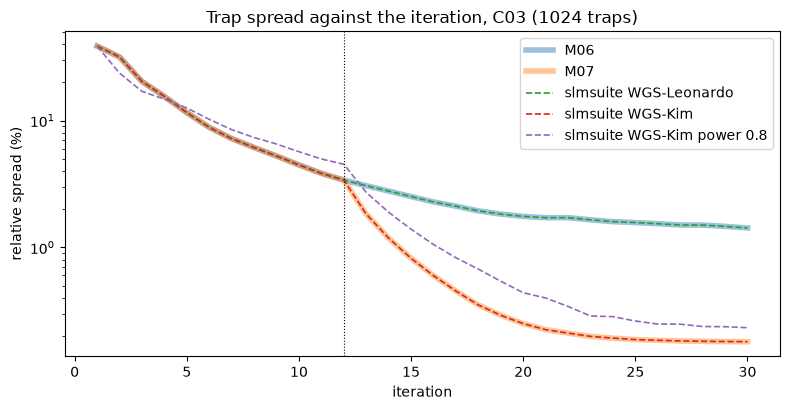

In [7]:
# the spread against the iteration, first seed of each method, on a log axis
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, curves in rows.items():
    style = {"lw": 1.2, "ls": "--"} if name.startswith("slmsuite") else {"lw": 4.0, "alpha": 0.45}
    ax.semilogy(np.arange(1, 31), [row[2] for row in curves[0]], label=name, **style)
print("relative spread (%) in the first iterations, first seed:")
for k in (1, 2, 3, 4, 5, 6, 8, 12):
    print(f"iteration {k:2d}: " + ", ".join(f"{name} {curves[0][k - 1][2]:.2f}" for name, curves in rows.items()))
ax.axvline(12, color="k", ls=":", lw=0.8)
ax.set_xlabel("iteration")
ax.set_ylabel("relative spread (%)")
ax.set_title("Trap spread against the iteration, C03 (1024 traps)")
ax.legend()
fig.tight_layout()
plt.show()

Each of DinHot's curves is covered by its slmsuite counterpart along the whole run: M06 by WGS-Leonardo, M07 by WGS-Kim, so that only the wide pale line shows around the thin dashed one; the printed iterations agree to two decimals, and the table's largest differences of 0.00001 and 0.00002 percentage points say the same over the whole run. Up to the dotted line the four runs at the power 1 are the same weighted update; at iteration 12 the phase-fixed pair bends downward at once, while the pair without freezing continues slowly and ends near 1.4 percent: this is the effect of freezing the phase. The fifth curve, WGS-Kim at slmsuite's default power 0.8, starts the same update with a softer correction, falls faster for the first three iterations (23.62 against 31.67 percent at iteration 2, and below the others at iterations 2 to 4), lies above the others from iteration 5 to the freeze (12.56 against 11.54 percent at iteration 5, 4.52 against 3.39 at iteration 12), and ends above M07, at 0.218 against 0.183 percent: the default flag alone moves the result by about a fifth, more than any difference between the two codes.

The second figure draws the histogram of the 1024 trap powers, divided by their mean, after 30 iterations, for M07 and for slmsuite's WGS-Kim on the first seed, on one shared axis.

M07: min 0.9945, max 1.0041 of the mean
slmsuite WGS-Kim: min 0.9945, max 1.0041 of the mean


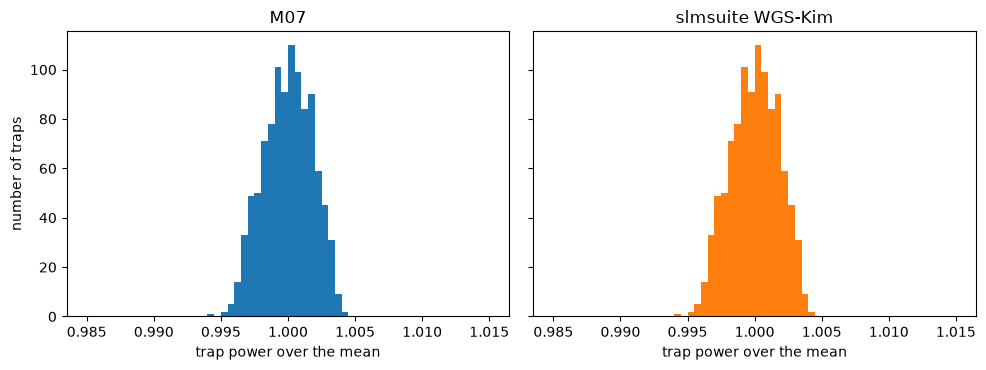

In [8]:
# the power of the 1024 traps after 30 iterations, M07 and slmsuite's WGS-Kim, relative to the mean, on one shared axis
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)
shown = (("M07", product["M07"][0].phi), ("slmsuite WGS-Kim", final_phase[("WGS-Kim", seeds[0])]))
edges = np.linspace(0.985, 1.015, 61)
for ax, (name, phi) in zip(axes, shown):
    i = metrics.trap_intensities(forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, traps))
    ax.hist(i / i.mean(), bins=edges, color="C0" if name == "M07" else "C1")
    ax.set_title(name)
    ax.set_xlabel("trap power over the mean")
    print(f"{name}: min {i.min() / i.mean():.4f}, max {i.max() / i.mean():.4f} of the mean")
axes[0].set_ylabel("number of traps")
fig.tight_layout()
plt.show()


The two histograms are the same: the weakest trap is at 0.9945 of the mean and the strongest at 1.0041 in both, and the bars coincide bin by bin, as they must for two phases that agree to the fifth digit of the spread. Nearly all the traps lie within half a percent of the mean power. The figure shows the final state only; how many iterations each needs is in the table's last column, 15 for both.

## Results

**Answer:** Yes. From the same start phase, on the same 1024 traps of C03, the same grid and the same Gaussian beam, DinHot's phase-fixed M07 and slmsuite's WGS-Kim at the weight power of the papers reach the same hologram: an efficiency of 0.7934, a uniformity of 0.9952 and a spread of 0.183 percent on the mean of two seeds (0.180 and 0.187), with final spreads that differ by at most 0.00002 percentage points, and both bring the spread under 1 percent at iteration 15. DinHot's weighted M06 and slmsuite's WGS-Leonardo agree in the same way (1.429 percent, at most 0.00001 apart) and do not get under 1 percent in 30 iterations. At slmsuite's default power 0.8, WGS-Kim ends at 0.218 percent and needs 17 iterations, so a comparison at the library's defaults compares two variants of the algorithm, not two codes. The freezing iteration matters: with $N = 12$ the spread is 0.180 percent at iteration 30 on the first seed, with $N = 6$ it is 2.106 percent, and with $N = 20$ it is 0.156 percent. The implementation in the product is the state of the art; the notebook does not show that it is better.

## Summary

Freezing the focal phase after a dozen iterations turns the slow tail of weighted Gerchberg-Saxton into a fast fall to a few tenths of a percent. Run from the same start, with the weight power the papers write, DinHot's M07 and M06 compute the same holograms as slmsuite's WGS-Kim and WGS-Leonardo to the fifth digit, so M07 is the state-of-the-art baseline of the later notebooks as it stands; a comparison at slmsuite's default power, or from different starts, measures something else. What the comparison does not cover is the quality of the freezing rule on arrays that are not crowded, a camera in the loop, or an SLM that is not ideal: the last of these is the subject of the next notebook, where the device model enters the loop itself.

## References

- Kim, Kim, Lee and Ahn, "Gerchberg-Saxton algorithm with phase fixing for tweezer arrays", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- Manetsch et al., "A tweezer array with 6100 highly coherent atomic qubits" (2025), https://arxiv.org/abs/2403.12021.
- slmsuite 0.5.0 (MIT), https://pypi.org/pypi/slmsuite/json and https://pypi.org/project/slmsuite/.